<a href="https://colab.research.google.com/github/Rayy505/K-Morph/blob/main/PCD_Assignment03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Image Segmentation with K-means Clustering and Morphological Operations**

# Import Libraries

In [61]:
import numpy as np                # Handles image data as multidimensional arrays and performs mathematical operations
import matplotlib.pyplot as plt   # Display results as plots
from PIL import Image             # loads images and converts them to RGB format
from google.colab import files    # For uploading images directly to google colab
import os                         # operating system and file management

In [62]:
print("Upload the image you want to process: ")
uploaded = files.upload()

for fn in uploaded.keys():
  print(f'Uploaded file "{fn}" with length {len(uploaded[fn])} bytes'.format(name=fn, length=len(uploaded[fn])))

Upload the image you want to process: 


Saving people in bazaar to people in bazaar
Uploaded file "people in bazaar" with length 1537954 bytes


# Configurations:

In [63]:
try:
  if 'uploaded' in globals() and uploaded:
    IMAGE_PATH = list(uploaded.keys())[0]     # Specifies the image to be processed
except Exception:
  pass

K = 4                                         # Number of clusters generated by K-means
MAX_ITERATIONS = 100                          # K-means iterations
RANDOM_SEED = 42

TARGET_CLUSTER = 1                            # Specifies which cluster to segment

KERNEL_SIZE = 3                               # 3x3 kernel

This section establishes the parameters that will be used throughout the image processing implementation.

# Image Loading:

In [64]:
def load_image(path):
  display_image = Image.open(path).convert("RGB") # Load original image and convert to RGB
  display_image = np.array(display_image)         # Convert image to NumPy array
  processing_image = display_image.copy()         # Create a separate processing image

  return display_image, processing_image

Loads the image and prepares two separate image representations:


*   `display_image` stores the original image in RGB format.
*   `processing_image` creates a copy of the original image that will be used for the image processing implementation.

Separating them prevents modifications made during image processing from affecting the original image. This allows the application to use processed data for segmentation while retaining the original RGB information for visualization.



# K-means Clustering:

In [65]:
def kmeans_segmentation(image, k, max_iterations=100):
  height, width, channels = image.shape
  pixels = image.reshape(-1, channels).astype(np.float64)         # Flatten image into a collection of RGB pixels

  np.random.seed(RANDOM_SEED)                                     # Initialize random centroids

  random_indices = np.random.choice(
    len(pixels),
    k,
    replace=False
  )

  centroids = pixels[random_indices].copy()
  labels = np.zeros(len(pixels), dtype=np.int32)
  for iteration in range(max_iterations):
    distances = np.sqrt(                                          # Calculate Euclidean distance to each centroid
      np.sum(
        (pixels[:, np.newaxis] - centroids) ** 2, axis=2
      )
    )
    new_labels = np.argmin(distances, axis=1)                    # Assign pixels to nearest centroid
    new_centroids = np.zeros_like(centroids)                     # Recalculate centroids

    for cluster in range(k):
      cluster_pixels = pixels[new_labels == cluster]
      if len(cluster_pixels) > 0:
        new_centroids[cluster] = np.mean(
          cluster_pixels,
          axis=0
        )
      else:
        new_centroids[cluster] = pixels[                         # Reinitialize an empty cluster
          np.random.randint(len(pixels))
        ]

    if np.array_equal(new_labels, labels) and np.allclose(       # Check convergence
      new_centroids, centroids
    ):
      centroids = new_centroids
      labels = new_labels
      break

    labels = new_labels
    centroids = new_centroids

  segmented_labels = labels.reshape(height, width)               # Reshape labels into the original image dimensions

  return segmented_labels, centroids

The main segmentation algorithm function. It begins by retrieving the image dimensions and converting the image into a collection of individual pixels.


*   `reshape(-1, channels)` transforms the image from a two-dimensional spatial
arrangement into a one-dimensional list of RGB pixels. Each pixel is represented by three numerical values.
*   The algorithm then randomly selects K pixels to serve as the initial cluster centroids.
*   A centroid represents the average color of a cluster. Each pixel will eventually be assigned to the cluster whose centroid has the smallest color distance.
*   The labels array stores the cluster assignment for every pixel.





# Binary Segmentation Mask:

In [66]:
def create_mask(labels, target_cluster):
  mask = np.zeros(labels.shape, dtype=np.uint8)
  mask[labels == target_cluster] = 1
  return mask

This function converts the K-means clustering result into a binary segmentation mask.

*   It initially creates an array filled with zeros, representing the background.
*   It then identifies pixels belonging to the selected cluster and assigns them a value of 1, representing the foreground.

*   The resulting mask contains only two possible values:
    - 0: Background.
    - 1: Selected foreground region.
    
This binary representation is necessary because morphological operations work by examining and modifying the arrangement of foreground and background pixels.

# Dilation & Erosion:

In [67]:
def dilation(image, kernel_size=3):
  height, width = image.shape
  padding = kernel_size // 2
  padded = np.pad(
    image,
    padding,
    mode="constant",
    constant_values=0
  )

  result = np.zeros_like(image)

  for y in range(height):
    for x in range(width):
      neighborhood = padded[
        y:y + kernel_size,
        x:x + kernel_size
      ]

      result[y, x] = np.max(neighborhood)

  return result

def erosion(image, kernel_size=3):
  height, width = image.shape
  padding = kernel_size // 2
  padded = np.pad(
    image,
    padding,
    mode="constant",
    constant_values=0
  )

  result = np.zeros_like(image)

  for y in range(height):
    for x in range(width):
      neighborhood = padded[
        y:y + kernel_size,
        x:x + kernel_size
      ]

      result[y, x] = np.min(neighborhood)

  return result

Dilation expands the foreground regions of a binary image.

*   First, the function retrieves the image dimensions and calculates the padding required to process pixels along the image boundaries.

*   `np.pad()` adds a border of zeros around the image.

*   The function then iterates through every pixel and extracts its surrounding neighborhood based on the specified kernel size.

*   `np.max()` determines the maximum value within that neighborhood.

*   Since foreground pixels have a value of 1, a pixel becomes foreground if at least one pixel in its neighborhood is foreground.

Consequently, dilation expands white regions and reduces small gaps between nearby foreground areas.

Erosion performs the opposite operation of dilation by shrinking foreground regions.

*   Similar to dilation, the function examines the neighborhood surrounding every pixel using the specified kernel size.

* But instead of finding the maximum value, it uses `np.min()` to determine the minimum value within the neighborhood.

* A pixel remains foreground only when every pixel in its neighborhood is foreground. If even one pixel is background, the resulting pixel becomes background.

Consequently, erosion reduces the size of foreground regions and can eliminate small isolated foreground objects.

# Opening & Closing:

In [68]:
def opening(image, kernel_size=3):
  eroded = erosion(image, kernel_size)
  result = dilation(eroded, kernel_size)

  return result

def closing(image, kernel_size = 3):
  dilated = dilation(image, kernel_size)
  result = erosion(dilated, kernel_size)

  return result

**Opening** and **closing** combine **erosion** and **dilation** in different sequences to achieve more specific segmentation improvements.

Opening consists of two consecutive morphological operations: erosion followed by dilation.

* First, **erosion** removes small foreground regions and reduces the size of existing objects.

* **Dilation** is then applied to restore the size of the remaining foreground regions.

The main purpose of opening is to remove small foreground noise while preserving larger structures.

For example, it can eliminate small isolated white pixels surrounding an object without completely removing the object itself.

Closing performs the reverse sequence of opening: dilation followed by erosion.

* First, **dilation** expands foreground regions, allowing nearby regions to connect and small gaps to become filled.

* **Erosion** is then applied to restore the approximate original size of the foreground objects.

The main purpose of closing is to fill small holes and gaps within foreground regions while maintaining their overall shapes.

# RGB Visualization:

In [69]:
def create_rgb_result(display_image, mask):
  result = np.zeros_like(display_image)         # Create an RGB result with a black background
  result[mask == 1] = display_image[mask == 1]  # Preserve original RGB values for foreground pixels

  return result

This function reconstructs an RGB image using the original image and the binary segmentation mask.

* First, `np.zeros_like(display_image)` creates a completely black RGB image with the same dimensions as the original image.

* The next line uses the binary mask to identify foreground pixels and copies their original RGB values from display_image into the result.

  As a result:
  - Foreground pixels retain their original RGB colors.
  - Background pixels remain black.
  - The resulting image has three color channels.
This allows the application to display segmentation results in RGB without having to reconstruct or estimate the original colors.

# RGB Overlay:

In [70]:
def create_rgb_overlay(display_image, mask):
    result = (display_image * 0.25).astype(np.uint8)  # Dim the background
    result[mask == 1] = display_image[mask == 1]      # Preserve original colors in segmented regions

    return result

This function creates a visualization that retains the entire original image while emphasizing the segmented foreground.

* First, the original image is multiplied by 0.25, reducing the brightness of every pixel to approximately 25% of its original intensity.

* The `astype(np.uint8)` operation converts the resulting values back into the standard 8-bit image format.

* The function then uses the binary mask to restore the original RGB values of all foreground pixels.

* Consequently, the segmented regions retain their original brightness and colors, while the background becomes darker.

This creates a visual overlay that makes it easier to identify which parts of the original image have been selected by the segmentation algorithm.

This is the function responsible for the colored segmentation results in your comparison screenshots.

# Display Results:

In [71]:
def display_results(
  display_image,
  labels,
  original_mask,
  morphological_results,
  centroids
):

  # Generate a cluster visualization
  cluster_map = centroids[labels].astype(np.uint8)

  # Generate RGB segmentation results
  results = {
      "Without Morphology": original_mask
  }

  results.update(morphological_results)

  # Prepare figure
  fig, axes = plt.subplots(
      2, 7,
      figsize=(22, 8)
  )

  # First row: RGB images
  images = [
      display_image,
      cluster_map,
      create_rgb_overlay(display_image, original_mask),
  ]

  titles = [
      "Original RGB",
      "K-means Clusters",
      "Without Morphology",
  ]

  for operation, mask in morphological_results.items():

      images.append(create_rgb_overlay(display_image, mask))
      titles.append(operation)

  for index, (image, title) in enumerate(zip(images, titles)):

      axes[0, index].imshow(image)
      axes[0, index].set_title(title, fontsize=10)
      axes[0, index].axis("off")

  # Second row: Binary masks
  axes[1, 0].axis("off")
  axes[1, 1].axis("off")

  for index, (title, mask) in enumerate(results.items()):

      axes[1, index + 2].imshow(
          mask,
          cmap="gray",
          vmin=0,
          vmax=1
      )

      axes[1, index + 2].set_title(
          title + " Mask",
          fontsize=9
      )

      axes[1, index + 2].axis("off")

  plt.tight_layout()
  plt.show()

This function collects the original image, K-means clustering results, and morphological processing results to display them in a single comparison figure. This allows us to visually examine how each morphological operation changes the original segmentation.

# Main:

This main function connects all the previously defined functions into one executable workflow.

Image loaded successfully!
Image dimensions: (2576, 3864, 3)

K-means clustering completed!
Cluster 0: Centroid RGB = [28 24 27], Pixels = 4143217
Cluster 1: Centroid RGB = [200 201 209], Pixels = 2367149
Cluster 2: Centroid RGB = [ 90 111 135], Pixels = 1971157
Cluster 3: Centroid RGB = [206 123  56], Pixels = 1472141

Segmentation mask generated!
Morphological processing completed!


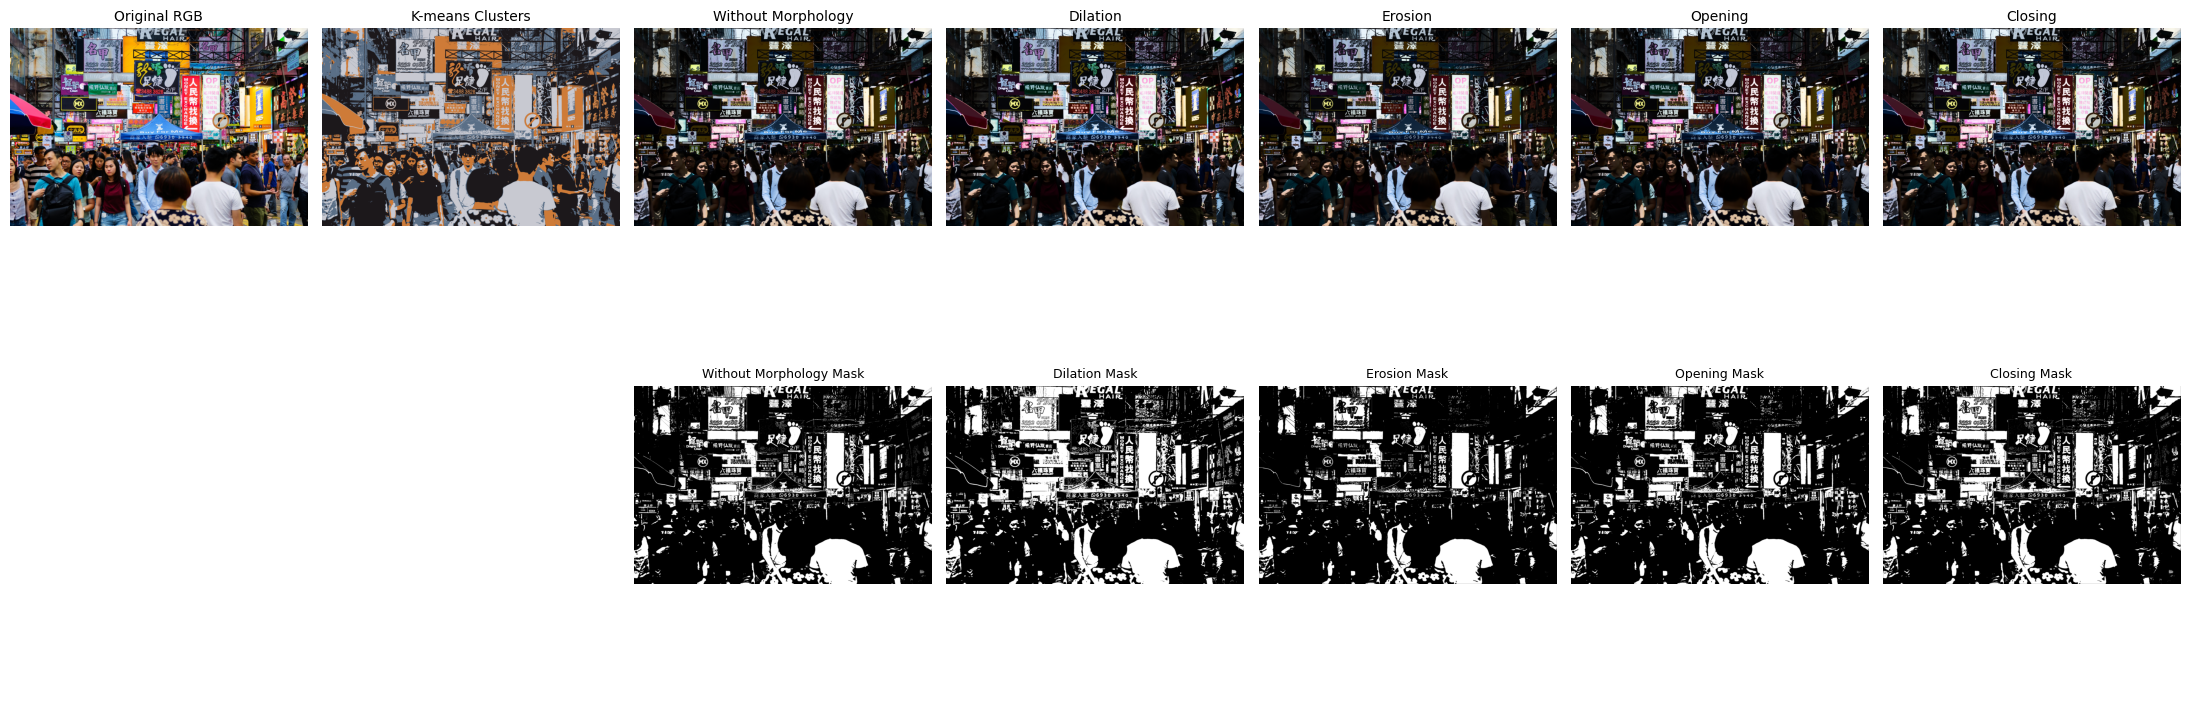

In [72]:
def main():

  # 1. Load image
  display_image, processing_image = load_image(IMAGE_PATH)

  print("Image loaded successfully!")
  print("Image dimensions:", processing_image.shape)

  # 2. Perform K-means segmentation
  labels, centroids = kmeans_segmentation(
      processing_image,
      K,
      MAX_ITERATIONS
  )

  print("\nK-means clustering completed!")

  # Display cluster information
  for i, centroid in enumerate(centroids):

      pixel_count = np.sum(labels == i)

      print(
          f"Cluster {i}: "
          f"Centroid RGB = {centroid.astype(int)}, "
          f"Pixels = {pixel_count}"
      )

  # 3. Generate binary segmentation mask
  original_mask = create_mask(
      labels,
      TARGET_CLUSTER
  )

  print("\nSegmentation mask generated!")

  # 4. Apply morphological operations
  dilation_result = dilation(
      original_mask,
      KERNEL_SIZE
  )

  erosion_result = erosion(
      original_mask,
      KERNEL_SIZE
  )

  opening_result = opening(
      original_mask,
      KERNEL_SIZE
  )

  closing_result = closing(
      original_mask,
      KERNEL_SIZE
  )

  # 5. Store morphological results
  morphological_results = {

      "Dilation": dilation_result,

      "Erosion": erosion_result,

      "Opening": opening_result,

      "Closing": closing_result

  }

  print("Morphological processing completed!")

  # 6. Compare results
  display_results(
      display_image,
      labels,
      original_mask,
      morphological_results,
      centroids
  )


if __name__ == "__main__":
  main()

# **How does the application preserve the original RGB colors?**


---


The application uses two separate image representations and a binary mask to combine image processing results with the original image.

The segmentation algorithm determines which pixels are retained, while the original RGB image supplies their color information:


* If the binary mask pixel is 1, the application copies that original RGB value into the final result.

* If the mask pixel is 0, the position remains black (in `create_rgb_result`) or dimmed (in `create_rgb_overlay`).

